In [ ]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

In [ ]:
import torch
import torch.nn as nn

from src.dataset import ALL_CLASSES, SpeechCommandsDatasetFactory
from src.model import SincResNetKWS
from src.train import train, validate
from src.visualization import plot_loss, plot_metrics

In [2]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
model = SincResNetKWS(num_classes=12).to(DEVICE)

In [4]:
print(model)

SincResNetKWS(
  (backbone): Sequential(
    (sincconv): SincConv1d(out_channels=80, kernel_size=251, sample_rate=16000, min_low_hz=50.0, min_band_hz=50.0, stride=10, normalize=False)
    (stem): Sequential(
      (0): Conv1d(80, 128, kernel_size=(5,), stride=(1,), padding=(2,), bias=False)
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (stage1): Sequential(
      (0): ResBlock1D(
        (bn1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (act1): LeakyReLU(negative_slope=0.01)
        (conv1): Conv1d(128, 128, kernel_size=(5,), stride=(1,), padding=(2,), bias=False)
        (bn2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (act2): LeakyReLU(negative_slope=0.01)
        (dropout): Dropout1d(p=0.05, inplace=False)
        (conv2): Conv1d(128, 128, kernel_size=(5,), stride=(1,), padding=(2,), bias=False)

In [5]:
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Trainable parameters: {num_params:,}")

Trainable parameters: 4,763,821


In [6]:
factory = SpeechCommandsDatasetFactory("train")

train_dataset = factory.train(skip_anomalies=True)
val_dataset = factory.val(skip_anomalies=True)
test_dataset = factory.test(skip_anomalies=True)

In [7]:
from torch.utils.data import DataLoader

batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    pin_memory=torch.cuda.is_available(),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=torch.cuda.is_available(),
)

In [11]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-4,
    weight_decay=1e-4,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
)

In [ ]:
epochs = 10

history = train(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    scheduler,
    DEVICE,
    epochs,
    "../sincnet.pt",
)


Epoch 1/10


train loss=1.6571 | train F1=0.4135 | train P=0.4181 | train R=0.4310
val   loss=1.0436 | val   F1=0.6447 | val   P=0.6743 | val   R=0.6559
Saved best model. val F1=0.6447

Epoch 2/10


train loss=0.7255 | train F1=0.7640 | train P=0.7637 | train R=0.7688
val   loss=0.5477 | val   F1=0.8337 | val   P=0.8438 | val   R=0.8338
Saved best model. val F1=0.8337

Epoch 3/10


train loss=0.4545 | train F1=0.8575 | train P=0.8572 | train R=0.8588
val   loss=0.4153 | val   F1=0.8611 | val   P=0.8715 | val   R=0.8638
Saved best model. val F1=0.8611

Epoch 4/10


train loss=0.3582 | train F1=0.8875 | train P=0.8872 | train R=0.8882
val   loss=0.3995 | val   F1=0.8769 | val   P=0.8879 | val   R=0.8768
Saved best model. val F1=0.8769

Epoch 5/10


...

train loss=0.2626 | train F1=0.9188 | train P=0.9188 | train R=0.9191
val   loss=0.3097 | val   F1=0.9061 | val   P=0.9092 | val   R=0.9060

Epoch 7/10


train loss=0.2385 | train F1=0.9251 | train P=0.9250 | train R=0.9252
val   loss=0.3221 | val   F1=0.8993 | val   P=0.9090 | val   R=0.8997

Epoch 8/10


train loss=0.2075 | train F1=0.9353 | train P=0.9353 | train R=0.9355
val   loss=0.3327 | val   F1=0.9020 | val   P=0.9106 | val   R=0.9018

Epoch 9/10


train loss=0.1454 | train F1=0.9561 | train P=0.9561 | train R=0.9562
val   loss=0.2175 | val   F1=0.9318 | val   P=0.9335 | val   R=0.9316
Saved best model. val F1=0.9318

Epoch 10/10


train loss=0.1250 | train F1=0.9627 | train P=0.9627 | train R=0.9627
val   loss=0.2193 | val   F1=0.9323 | val   P=0.9329 | val   R=0.9324
Saved best model. val F1=0.9323


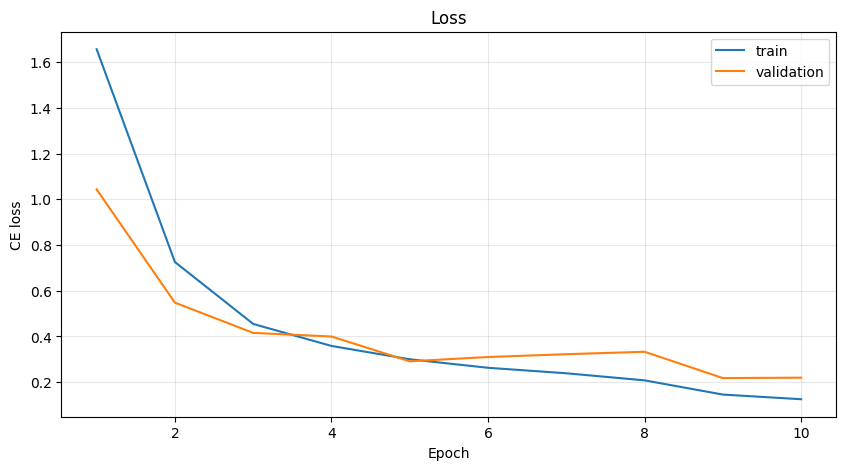

In [10]:
plot_loss(history)

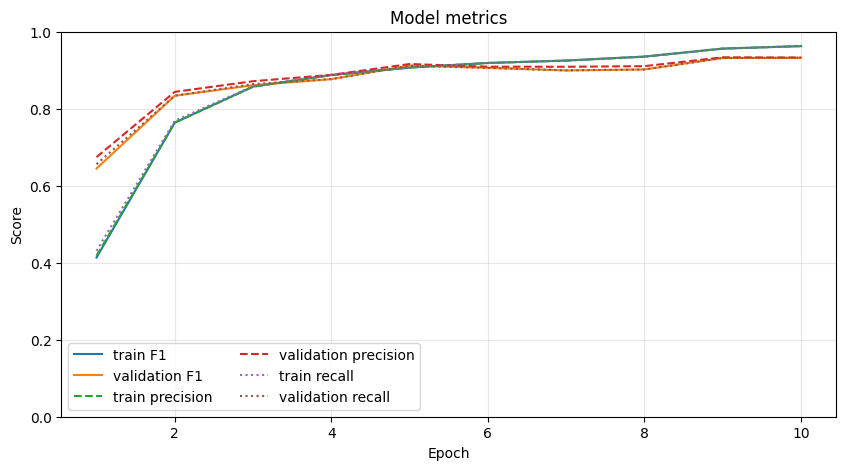

In [11]:
plot_metrics(history)

In [ ]:
checkpoint = torch.load("../sincnet.pt", map_location="cpu")

model.load_state_dict(checkpoint["model_state_dict"])

model = model.to(DEVICE)

In [16]:
test_loss, test_metrics, test_true, test_pred = validate(
    model=model,
    loader=test_loader,
    criterion=criterion,
    device=DEVICE,
)

print(f"Test loss      : {test_loss:.4f}")

print(f"Test accuracy  : {test_metrics['accuracy']:.4f}")

print(f"Test precision : {test_metrics['precision']:.4f}")

print(f"Test recall    : {test_metrics['recall']:.4f}")

print(f"Test F1        : {test_metrics['f1']:.4f}")

Test loss      : 0.1992
Test accuracy  : 0.9372
Test precision : 0.9374
Test recall    : 0.9372
Test F1        : 0.9371


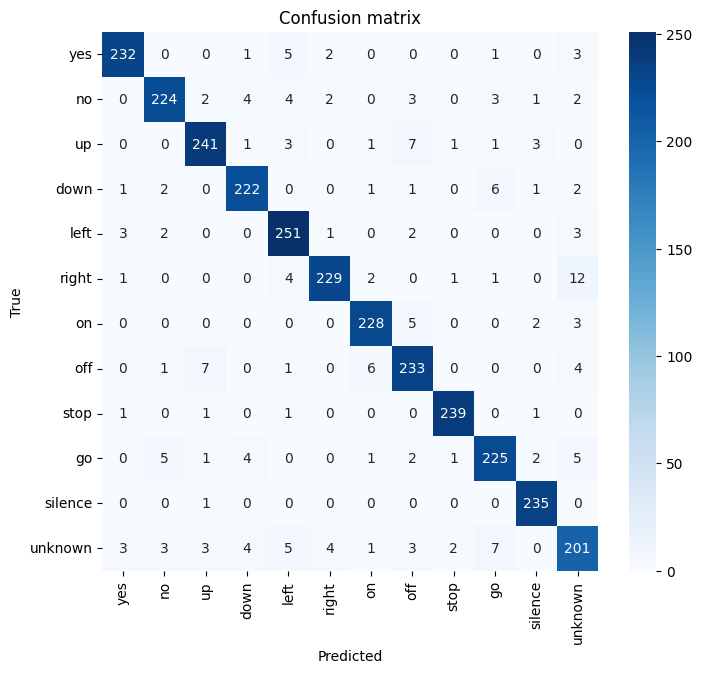

In [13]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(test_true, test_pred)

plt.figure(figsize=(8, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=ALL_CLASSES,
    yticklabels=ALL_CLASSES,
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix")
plt.show()